In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import torch

print("GPU Available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")

GPU Available: True
GPU: Tesla T4


In [2]:
import os

print("INPUT DATASETS:")

for root, dirs, files in os.walk("/kaggle/input"):
    level = root.replace("/kaggle/input", "").count(os.sep)

    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")

    if level >= 3:
        dirs[:] = []

print("\nWORKING FOLDERS:")

for item in os.listdir("/kaggle/working"):
    print(item)

INPUT DATASETS:
input/

WORKING FOLDERS:
.virtual_documents


In [3]:
import os
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nDataset contents:")

for item in os.listdir("/kaggle/input"):
    print(item)

GPU available: True
GPU: Tesla T4

Dataset contents:
datasets
notebooks


In [5]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    level = root.replace("/kaggle/input", "").count(os.sep)

    if level <= 4:
        print(root)
        for f in files[:5]:
            print("   ", f)

    if level >= 4:
        dirs[:] = []

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/ramsaikoravi
/kaggle/input/datasets/ramsaikoravi/ffpp-c0-gold-standard-benchmark
    README.md
/kaggle/input/datasets/ramsaikoravi/ffpp-c0-gold-standard-benchmark/c0
    README.md
    dataset_summary.json
    manifest.csv
/kaggle/input/datasets/ramsaikoravi/ffpp-c0-gold-standard-benchmark/c23
    README.md
    dataset_summary.json
    manifest.csv
/kaggle/input/datasets/ramsaikoravi/ffpp-c0-gold-standard-benchmark/c40
    README.md
    dataset_summary.json
    manifest.csv
/kaggle/input/notebooks
/kaggle/input/notebooks/clonesang
/kaggle/input/notebooks/clonesang/deepfake-video-detection-major
    __notebook__.ipynb
    __output__.json
    __results__.html
    best_model.keras
    custom.css
/kaggle/input/notebooks/clonesang/deepfake-video-detection-major/__results___files
    __results___15_3.png
    __results___16_0.png
    __results___21_1.png
    __results___21_3.png
    __results___21_5.png


In [6]:
import pandas as pd
import os

DATASET_PATH = "/kaggle/input/datasets/ramsaikoravi/ffpp-c0-gold-standard-benchmark/c23"

df = pd.read_csv(os.path.join(DATASET_PATH, "manifest.csv"))

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset summary:")
with open(os.path.join(DATASET_PATH, "README.md")) as f:
    print(f.read()[:3000])
    

Dataset shape: (6000, 11)

Column names:
['sample_id', 'tier', 'compression', 'video_path', 'split', 'label', 'class_name', 'manipulation_type', 'source_donor_video', 'sha256', 'size_mb']

First 5 rows:


,sample_id,tier,compression,video_path,split,label,class_name,manipulation_type,source_donor_video,sha256,size_mb
0,NaN,c23,c23,c23/real/012.mp4,test,1,real,Authentic_YouTube_Sequence,NAN,ccb577e758e8918bc3671b0e2c496973ca032adb9d53c7...,0.69
1,NaN,c23,c23,c23/real/009.mp4,train,1,real,Authentic_YouTube_Sequence,NAN,825a2a3155cc858cc865f9e75f1a7226cfc819bdd2580e...,0.74
2,NaN,c23,c23,c23/real/006.mp4,train,1,real,Authentic_YouTube_Sequence,NAN,581ad4825e104e2a34daf865de5deb83a943bf4cbefb0b...,0.82
3,NaN,c23,c23,c23/real/007.mp4,train,1,real,Authentic_YouTube_Sequence,NAN,88994bbd1e1a77a4a41c8c13c63b596d21caf2005944bc...,1.02
4,NaN,c23,c23,c23/real/005.mp4,train,1,real,Authentic_YouTube_Sequence,NAN,130aa380bd35c326fc7080370a030e06a32920d88675d1...,1.51



Dataset summary:
# FaceForensics++ c23 Gold-Standard Benchmark (6,000 Clips)

## Overview
This tier contains the **High-Quality (c23)** compressed benchmark from the official FaceForensics++ forensic repository.
It provides **6,000 video sequences** (1,000 authentic original clips and 5,000 manipulated clips across 5 methods) compressed with H.264 Constant Rate Factor (CRF) 23, simulating standard high-definition web sharing.

## Directory Structure
```
c23/
├── real/                  (1,000 pristine clips: 000.mp4 to 999.mp4)
├── fake/                  (5,000 manipulated clips across 5 methods):
│    ├── Deepfakes/        (1,000 clips)
│    ├── Face2Face/        (1,000 clips)
│    ├── FaceSwap/         (1,000 clips)
│    ├── NeuralTextures/   (1,000 clips)
│    └── FaceShifter/      (1,000 clips)
├── manifest.csv           (Master audit table with SHA256 hashes & splits)
├── dataset_summary.json   (Certified research scorecard)
└── README.md              (Tier documentation)
```



In [7]:
import pandas as pd
import os

print("Split counts:")
print(df["split"].value_counts())

print("\nLabels:")
print(df.groupby(["split", "class_name"]).size())

print("\nManipulation types:")
print(df["manipulation_type"].value_counts())

print("\nChecking video paths:")

for i in range(5):
    relative_path = df.iloc[i]["video_path"]
    possible_path = os.path.join(DATASET_PATH, relative_path)
    print(relative_path, "->", os.path.exists(possible_path))

print("\nDataset directories:")
print(os.listdir(DATASET_PATH))

Split counts:
split
train    4320
test      840
val       840
Name: count, dtype: int64

Labels:
split  class_name
test   fake           700
       real           140
train  fake          3600
       real           720
val    fake           700
       real           140
dtype: int64

Manipulation types:
manipulation_type
Authentic_YouTube_Sequence    1000
Deepfakes                     1000
Face2Face                     1000
FaceSwap                      1000
NeuralTextures                1000
FaceShifter                   1000
Name: count, dtype: int64

Checking video paths:
c23/real/012.mp4 -> False
c23/real/009.mp4 -> False
c23/real/006.mp4 -> False
c23/real/007.mp4 -> False
c23/real/005.mp4 -> False

Dataset directories:
['README.md', 'dataset_summary.json', 'fake', 'manifest.csv', 'real']


In [8]:
import os
import cv2

def get_video_path(relative_path):
    relative_path = str(relative_path).replace("\\", "/")
    if relative_path.startswith("c23/"):
        relative_path = relative_path[4:]
    return os.path.join(DATASET_PATH, relative_path)

df["full_path"] = df["video_path"].apply(get_video_path)

print("Corrected paths:")
for path in df["full_path"].head(5):
    print(path, "Exists:", os.path.exists(path))

print("\nLabel mapping:")
print(df.groupby(["label", "class_name"]).size())

# Test reading one video
video = cv2.VideoCapture(df["full_path"].iloc[0])
success, frame = video.read()
video.release()

print("\nVideo readable:", success)
if success:
    print("Frame shape:", frame.shape)

Corrected paths:
/kaggle/input/datasets/ramsaikoravi/ffpp-c0-gold-standard-benchmark/c23/real/012.mp4 Exists: True
/kaggle/input/datasets/ramsaikoravi/ffpp-c0-gold-standard-benchmark/c23/real/009.mp4 Exists: True
/kaggle/input/datasets/ramsaikoravi/ffpp-c0-gold-standard-benchmark/c23/real/006.mp4 Exists: True
/kaggle/input/datasets/ramsaikoravi/ffpp-c0-gold-standard-benchmark/c23/real/007.mp4 Exists: True
/kaggle/input/datasets/ramsaikoravi/ffpp-c0-gold-standard-benchmark/c23/real/005.mp4 Exists: True

Label mapping:
label  class_name
0      fake          5000
1      real          1000
dtype: int64

Video readable: True
Frame shape: (480, 640, 3)


In [9]:
import os
import cv2
import random
import pandas as pd
from tqdm.auto import tqdm

random.seed(42)

OUTPUT_DIR = "/kaggle/working/xception_frames"

# Balanced training and evaluation samples
samples = {
    "train": {"fake": 500, "real": 500},
    "val": {"fake": 140, "real": 140},
    "test": {"fake": 140, "real": 140}
}

def extract_frame(video_path, save_path):
    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        return False

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames > 0:
        cap.set(cv2.CAP_PROP_POS_FRAMES, total_frames // 2)

    success, frame = cap.read()
    cap.release()

    if not success:
        return False

    frame = cv2.resize(frame, (299, 299))
    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    return cv2.imwrite(
        save_path,
        cv2.cvtColor(frame, cv2.COLOR_RGB2BGR)
    )

for split, classes in samples.items():
    for class_name, count in classes.items():

        subset = df[
            (df["split"] == split) &
            (df["class_name"] == class_name)
        ].sample(n=count, random_state=42)

        folder = os.path.join(OUTPUT_DIR, split, class_name)
        os.makedirs(folder, exist_ok=True)

        successful = 0

        for idx, row in tqdm(
            subset.iterrows(),
            total=len(subset),
            desc=f"{split}-{class_name}"
        ):
            filename = f"{row['sha256'][:16]}.jpg"
            save_path = os.path.join(folder, filename)

            if extract_frame(row["full_path"], save_path):
                successful += 1

        print(
            f"{split} | {class_name} | "
            f"Extracted: {successful}/{count}"
        )

print("\nFRAME EXTRACTION COMPLETED!")

train-fake:   0%|          | 0/500 [00:00<?, ?it/s]

train | fake | Extracted: 500/500


train-real:   0%|          | 0/500 [00:00<?, ?it/s]

train | real | Extracted: 500/500


val-fake:   0%|          | 0/140 [00:00<?, ?it/s]

val | fake | Extracted: 140/140


... (2 outputs left out)

test-fake:   0%|          | 0/140 [00:00<?, ?it/s]

test | fake | Extracted: 140/140


test-real:   0%|          | 0/140 [00:00<?, ?it/s]

test | real | Extracted: 140/140

FRAME EXTRACTION COMPLETED!


In [10]:
import os

for split in ["train", "val", "test"]:
    print("\n", split.upper())

    for cls in ["fake", "real"]:
        folder = os.path.join(OUTPUT_DIR, split, cls)
        count = len(os.listdir(folder))
        print(cls, ":", count)


 TRAIN
fake : 500
real : 500

 VAL
fake : 140
real : 140

 TEST
fake : 140
real : 140


In [11]:
!pip -q install timm

import torch
import timm

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))

models = timm.list_models("*xception*")
print("\nAvailable Xception models:")
print(models)

PyTorch: 2.11.0+cu130
GPU: Tesla T4

Available Xception models:
['legacy_xception', 'xception41', 'xception41p', 'xception65', 'xception65p', 'xception71']


In [12]:
import os
import torch
import timm
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

device = torch.device("cuda")

# Image preprocessing
train_transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# Load datasets
train_data = datasets.ImageFolder(
    OUTPUT_DIR + "/train",
    transform=train_transform
)

val_data = datasets.ImageFolder(
    OUTPUT_DIR + "/val",
    transform=test_transform
)

test_data = datasets.ImageFolder(
    OUTPUT_DIR + "/test",
    transform=test_transform
)

print("Class mapping:", train_data.class_to_idx)

assert train_data.class_to_idx == {"fake": 0, "real": 1}

train_loader = DataLoader(
    train_data, batch_size=16,
    shuffle=True, num_workers=2, pin_memory=True
)

val_loader = DataLoader(
    val_data, batch_size=16,
    shuffle=False, num_workers=2, pin_memory=True
)

test_loader = DataLoader(
    test_data, batch_size=16,
    shuffle=False, num_workers=2, pin_memory=True
)

# Load pretrained XceptionNet
try:
    model = timm.create_model(
        "legacy_xception",
        pretrained=True,
        num_classes=2
    )
except Exception as e:
    raise RuntimeError(
        "Pretrained weights could not load. "
        "Check Kaggle Internet settings. Error: " + str(e)
    )

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

scaler = torch.amp.GradScaler("cuda")

print("\nXceptionNet loaded successfully!")
print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Testing images:", len(test_data))
print("Device:", device)

Class mapping: {'fake': 0, 'real': 1}
Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth

XceptionNet loaded successfully!
Training images: 1000
Validation images: 280
Testing images: 280
Device: cuda


In [13]:
import numpy as np
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, roc_auc_score

EPOCHS = 5
best_auc = 0

for epoch in range(EPOCHS):

    model.train()
    running_loss = 0
    correct = 0
    total = 0

    progress = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}")

    for images, labels in progress:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda"):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        progress.set_postfix(loss=loss.item())

    train_acc = 100 * correct / total

    # Validation
    model.eval()
    y_true, y_prob = [], []

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device, non_blocking=True)

            with torch.amp.autocast("cuda"):
                outputs = model(images)

            probabilities = torch.softmax(
                outputs.float(), dim=1
            )[:, 1]

            y_true.extend(labels.numpy())
            y_prob.extend(probabilities.cpu().numpy())

    val_acc = accuracy_score(
        y_true, np.array(y_prob) >= 0.5
    ) * 100

    val_auc = roc_auc_score(y_true, y_prob)

    print(f"\nEpoch: {epoch+1}")
    print(f"Training Accuracy: {train_acc:.2f}%")
    print(f"Validation Accuracy: {val_acc:.2f}%")
    print(f"Validation ROC-AUC: {val_auc:.4f}")

    if val_auc > best_auc:
        best_auc = val_auc

        torch.save(
            model.state_dict(),
            "/kaggle/working/xception_best.pth"
        )

        print("Best model saved!")

print("\nTraining completed!")
print("Best Validation AUC:", best_auc)

Epoch 1/5:   0%|          | 0/63 [00:00<?, ?it/s]


Epoch: 1
Training Accuracy: 44.20%
Validation Accuracy: 52.14%
Validation ROC-AUC: 0.5305
Best model saved!


Epoch 2/5:   0%|          | 0/63 [00:00<?, ?it/s]


Epoch: 2
Training Accuracy: 61.90%
Validation Accuracy: 57.86%
Validation ROC-AUC: 0.6089
Best model saved!


Epoch 3/5:   0%|          | 0/63 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cdae470ef20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cdae470ef20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


Epoch: 3
Training Accuracy: 67.90%
Validation Accuracy: 56.07%
Validation ROC-AUC: 0.6545
Best model saved!


Epoch 4/5:   0%|          | 0/63 [00:00<?, ?it/s]


Epoch: 4
Training Accuracy: 76.00%
Validation Accuracy: 63.21%
Validation ROC-AUC: 0.7014
Best model saved!


Epoch 5/5:   0%|          | 0/63 [00:00<?, ?it/s]


Epoch: 5
Training Accuracy: 80.80%
Validation Accuracy: 64.64%
Validation ROC-AUC: 0.7093
Best model saved!

Training completed!
Best Validation AUC: 0.7093367346938776


In [14]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
import torch
import numpy as np

# Load the best saved model
model.load_state_dict(
    torch.load(
        "/kaggle/working/xception_best.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

y_true = []
y_pred = []
y_prob = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        with torch.amp.autocast("cuda"):
            outputs = model(images)

        probabilities = torch.softmax(outputs.float(), dim=1)[:, 1]
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())
        y_prob.extend(probabilities.cpu().numpy())

# Calculate evaluation metrics
accuracy = accuracy_score(y_true, y_pred) * 100
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
auc = roc_auc_score(y_true, y_prob)

print("========== XceptionNet Test Results ==========")
print(f"Test Accuracy: {accuracy:.2f}%")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"ROC-AUC: {auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Fake", "Real"],
    zero_division=0
))


========== XceptionNet Test Results ==========
Test Accuracy: 60.36%
Precision: 0.5838
Recall: 0.7214
F1 Score: 0.6454
ROC-AUC: 0.6292

Confusion Matrix:
[[ 68  72]
 [ 39 101]]

Classification Report:
              precision    recall  f1-score   support

        Fake       0.64      0.49      0.55       140
        Real       0.58      0.72      0.65       140

    accuracy                           0.60       280
   macro avg       0.61      0.60      0.60       280
weighted avg       0.61      0.60      0.60       280



<Figure size 600x500 with 0 Axes>

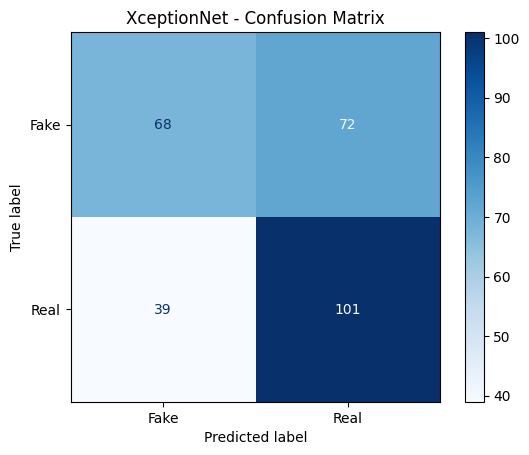

<Figure size 600x500 with 0 Axes>

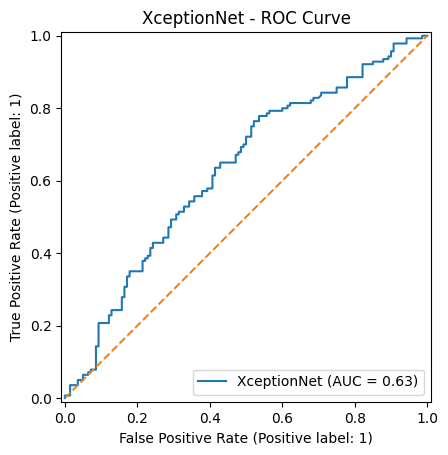

Both plots saved successfully!


In [15]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

# Confusion Matrix
plt.figure(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=["Fake", "Real"],
    cmap="Blues"
)
plt.title("XceptionNet - Confusion Matrix")
plt.savefig("/kaggle/working/xception_confusion_matrix.png",
            dpi=300, bbox_inches="tight")
plt.show()

# ROC Curve
plt.figure(figsize=(6, 5))
RocCurveDisplay.from_predictions(
    y_true,
    y_prob,
    name="XceptionNet"
)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("XceptionNet - ROC Curve")
plt.savefig("/kaggle/working/xception_roc_curve.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Both plots saved successfully!")


In [16]:
import os

model_path = "/kaggle/working/xception_best.pth"

if os.path.exists(model_path):
    print("XceptionNet model exists!")
    print("Model size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")
else:
    print("Model file not found!")

XceptionNet model exists!
Model size: 79.68 MB


In [17]:

import pandas as pd
import os

results = {
    "Model": ["XceptionNet"],
    "Training Epochs": [5],
    "Training Accuracy": [80.80],
    "Validation Accuracy": [64.64],
    "Validation ROC-AUC": [0.7093],
    "Test Accuracy": [60.36],
    "Precision": [0.5838],
    "Recall": [0.7214],
    "F1 Score": [0.6454],
    "Test ROC-AUC": [0.6292]
}

results_df = pd.DataFrame(results)

results_df.to_csv(
    "/kaggle/working/xception_results.csv",
    index=False
)

print("Results saved successfully!")
print(results_df.to_string(index=False))


Results saved successfully!
      Model  Training Epochs  Training Accuracy  Validation Accuracy  Validation ROC-AUC  Test Accuracy  Precision  Recall  F1 Score  Test ROC-AUC
XceptionNet                5               80.8                64.64              0.7093          60.36     0.5838  0.7214    0.6454        0.6292


In [1]:

!pip -q install reportlab

from reportlab.lib.pagesizes import A4
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image, Table, TableStyle
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import inch
import os

pdf_path = "/kaggle/working/XceptionNet_Project_Summary.pdf"

doc = SimpleDocTemplate(pdf_path, pagesize=A4)
styles = getSampleStyleSheet()
story = []

story.append(Paragraph(
    "XceptionNet - Deepfake Detection Module",
    styles["Title"]
))
story.append(Spacer(1, 15))

story.append(Paragraph("1. Overview", styles["Heading2"]))
story.append(Paragraph(
    "This module uses XceptionNet, a convolutional neural network, "
    "to classify video frames as real or fake. The model was initialized "
    "with pretrained ImageNet weights and fine-tuned on the selected "
    "FaceForensics++ C23 dataset subset.",
    styles["BodyText"]
))
story.append(Spacer(1, 12))

story.append(Paragraph("2. Dataset and Experimental Setup", styles["Heading2"]))
details = [
    ["Parameter", "Details"],
    ["Dataset", "FaceForensics++ C23"],
    ["Training images", "1,000 (500 fake, 500 real)"],
    ["Validation images", "280 (140 fake, 140 real)"],
    ["Test images", "280 (140 fake, 140 real)"],
    ["Total sampled images", "1,560"],
    ["Input image size", "299 x 299"],
    ["Model", "XceptionNet"],
    ["Optimizer", "AdamW"],
    ["Epochs", "5"],
    ["Hardware", "NVIDIA Tesla T4 GPU"]
]

table = Table(details, colWidths=[2*inch, 4*inch])
table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.lightgrey),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("PADDING", (0, 0), (-1, -1), 7),
]))
story.append(table)
story.append(Spacer(1, 12))

story.append(Paragraph("3. Evaluation Results", styles["Heading2"]))

metrics = [
    ["Metric", "Result"],
    ["Training Accuracy", "80.80%"],
    ["Validation Accuracy", "64.64%"],
    ["Validation ROC-AUC", "0.7093"],
    ["Test Accuracy", "60.36%"],
    ["Precision", "0.5838"],
    ["Recall", "0.7214"],
    ["F1 Score", "0.6454"],
    ["Test ROC-AUC", "0.6292"]
]

table2 = Table(metrics, colWidths=[2.5*inch, 2*inch])
table2.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.lightgrey),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("PADDING", (0, 0), (-1, -1), 7),
]))
story.append(table2)
story.append(Spacer(1, 12))

story.append(Paragraph("4. Confusion Matrix", styles["Heading2"]))
cm_path = "/kaggle/working/xception_confusion_matrix.png"
if os.path.exists(cm_path):
    story.append(Image(cm_path, width=4.5*inch, height=3.7*inch))
story.append(Spacer(1, 10))

story.append(Paragraph("5. ROC Curve", styles["Heading2"]))
roc_path = "/kaggle/working/xception_roc_curve.png"
if os.path.exists(roc_path):
    story.append(Image(roc_path, width=4.5*inch, height=3.7*inch))
story.append(Spacer(1, 10))

story.append(Paragraph("6. Conclusion and Limitations", styles["Heading2"]))
story.append(Paragraph(
    "The XceptionNet model completed five training epochs. "
    "It achieved 60.36% accuracy and 0.6292 ROC-AUC on the balanced "
    "held-out test subset. The difference between training, validation, "
    "and test performance indicates that further model improvement "
    "and generalization testing are needed. This experiment uses a "
    "limited sampled set of one frame per video and should not be "
    "interpreted as full-dataset or video-level performance.",
    styles["BodyText"]
))

doc.build(story)

print("PDF created successfully!")
print("File:", pdf_path)
print("Size:", round(os.path.getsize(pdf_path) / (1024*1024), 2), "MB")



PDF created successfully!
File: /kaggle/working/XceptionNet_Project_Summary.pdf
Size: 0.0 MB


In [2]:

import os

folder = "/kaggle/working"

print("Files available in Kaggle working directory:\n")

for file in os.listdir(folder):
    path = os.path.join(folder, file)

    if os.path.isfile(path):
        size = os.path.getsize(path) / (1024 * 1024)
        print(f"{file}  -  {size:.2f} MB")


Files available in Kaggle working directory:

XceptionNet_Project_Summary.pdf  -  0.00 MB


In [3]:

print("Checking saved training variables...")

for name in ["model", "y_true", "y_pred", "y_prob", "test_loader"]:
    print(name, "Available" if name in globals() else "Not available")


Checking saved training variables...
model Not available
y_true Not available
y_pred Not available
y_prob Not available
test_loader Not available
